<a href="https://colab.research.google.com/github/kph4br/Walmart-Midterm/blob/main/notebooks/working%20draft%20-%20Midterm%20Progress%20Lab%2010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

Setup Code (from previous lab)!

In [1]:
import subprocess, os
import pandas as pd, numpy as np, matplotlib.pyplot as plt

REPO_PATH = '/content/Walmart-Midterm'
if os.path.exists(REPO_PATH):
    subprocess.run(['git', '-C', REPO_PATH, 'pull'])
else:
    subprocess.run(['git', 'clone', 'https://github.com/kph4br/Walmart-Midterm', REPO_PATH])

# cleaning function from Lab 09
def load_and_clean_transactions(filepath):
    df = pd.read_csv(filepath)
    initial_rows = len(df)
    df['store_id'] = df['store_id'].str.upper().str.strip()
    if df['unit_price'].dtype == object:
        df['unit_price'] = df['unit_price'].astype(str).str.replace('$', '', regex=False).str.strip()
        df['unit_price'] = pd.to_numeric(df['unit_price'], errors='coerce')
    valid_qty_mask = df['quantity'] > 0
    returns_count = (~valid_qty_mask).sum()
    df = df[valid_qty_mask].copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', errors='coerce')
    df = df.drop_duplicates()
    print(f"Initial rows: {initial_rows}")
    print(f"Removed negative quantities/returns: {returns_count}")
    print(f"Final rows after cleaning: {len(df)}")
    return df

# store id cleaner from Lab 09
def clean_store_id(store_id):
    store_id = str(store_id).upper().strip()
    store_id = store_id.replace('-', '').replace('_', '').replace(' ', '')
    return store_id[:2] + '-' + store_id[2:]

cleaned_df = load_and_clean_transactions(f'{REPO_PATH}/data/walmart_transactions.csv')
cleaned_df['store_id'] = cleaned_df['store_id'].apply(clean_store_id)

# SKU -> canonical product
CANON = {
    'PT-12': 'Pop-Tarts', 'SKU#459812': 'Pop-Tarts', 'POPTART-STRAW': 'Pop-Tarts', 'PT_STRAWBERRY': 'Pop-Tarts',
    'WTR-24': 'Water 24pk', 'WATER24PK': 'Water 24pk', 'WTR_24PK': 'Water 24pk',
    'BATT-100': 'AA Batteries', 'BAT-AA4': 'AA Batteries', 'BATT_AA_4PK': 'AA Batteries',
    'FLASH-01': 'Flashlight', 'LED-FLASH': 'Flashlight',
    'BEER-24': 'Light Beer', 'LTBEER24': 'Light Beer',
    'BG-MONO': 'Monopoly', 'MONOPOLY-01': 'Monopoly', 'GAME-MONO': 'Monopoly',
    'CARDS-01': 'Playing Cards', 'PLAYCARD-STD': 'Playing Cards',
    'STREAM-01': 'Streaming Device', 'ROKU-STD': 'Streaming Device',
    'SOUP-CAN': 'Canned Soup', 'CNSOUP-01': 'Canned Soup',
    'BREAD-WH': 'White Bread', 'WHITEBREAD': 'White Bread',
    'PB-16': 'Peanut Butter', 'PNUTBTR-16': 'Peanut Butter',
    'CNDL-EM': 'Candles', 'CANDLE-EMRG': 'Candles',
    'FAID-01': 'First Aid Kit', 'FIRSTAID-KIT': 'First Aid Kit',
    'CHRG-PORT': 'Portable Charger', 'PORTCHARGER': 'Portable Charger',
    'CHIPS-VP': 'Chips', 'CHIPVARIETY': 'Chips',
    'PTOWEL-6': 'Paper Towels', 'PAPERTOWEL6': 'Paper Towels',
    'TP-12': 'Toilet Paper', 'TOILETPAPER12': 'Toilet Paper',
    'DIAP-S3': 'Diapers', 'DIAPERS-3': 'Diapers',
    'BFORM-01': 'Infant Formula', 'BABYFORMULA': 'Infant Formula',
    'TARP-HD': 'Tarp', 'HDTARP-01': 'Tarp',
}
cleaned_df['product'] = cleaned_df['sku'].map(CANON)
cleaned_df['date'] = cleaned_df['timestamp'].dt.normalize()

d = cleaned_df.dropna(subset=['date'])
print('Rows with a usable date:', len(d))

Initial rows: 25562
Removed negative quantities/returns: 130
Final rows after cleaning: 25402
Rows with a usable date: 24521


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [2]:
# TODO: the numbers
BASE_START, BASE_END = '2024-09-01', '2024-09-15'
SURGE_START, SURGE_END = '2024-09-21', '2024-09-26'

daily = d.pivot_table(index='date', columns='product', values='quantity', aggfunc='sum', fill_value=0)

q1 = pd.DataFrame({
    'baseline_avg': daily.loc[BASE_START:BASE_END].mean(),
    'surge_avg': daily.loc[SURGE_START:SURGE_END].mean(),
})
q1['multiple'] = q1['surge_avg'] / q1['baseline_avg']
q1 = q1.round(1).sort_values('multiple', ascending=False)

print('Baseline window:', BASE_START, 'to', BASE_END)
print('Surge window:   ', SURGE_START, 'to', SURGE_END)
all_base = daily.loc[BASE_START:BASE_END].sum(axis=1).mean()
all_surge = daily.loc[SURGE_START:SURGE_END].sum(axis=1).mean()
print(f'All products: {all_base:.0f} units/day -> {all_surge:.0f} units/day = {all_surge/all_base:.1f}x')
display(q1)

Baseline window: 2024-09-01 to 2024-09-15
Surge window:    2024-09-21 to 2024-09-26
All products: 1103 units/day -> 3030 units/day = 2.7x


,baseline_avg,surge_avg,multiple
product,,,
Pop-Tarts,73.3,438.0,6.0
Flashlight,57.1,203.5,3.6
Tarp,44.2,151.3,3.4
Water 24pk,107.7,349.8,3.2
Monopoly,42.9,131.8,3.1
AA Batteries,87.7,273.7,3.1
Portable Charger,42.7,124.7,2.9
Candles,57.4,163.2,2.8
Streaming Device,27.5,71.8,2.6


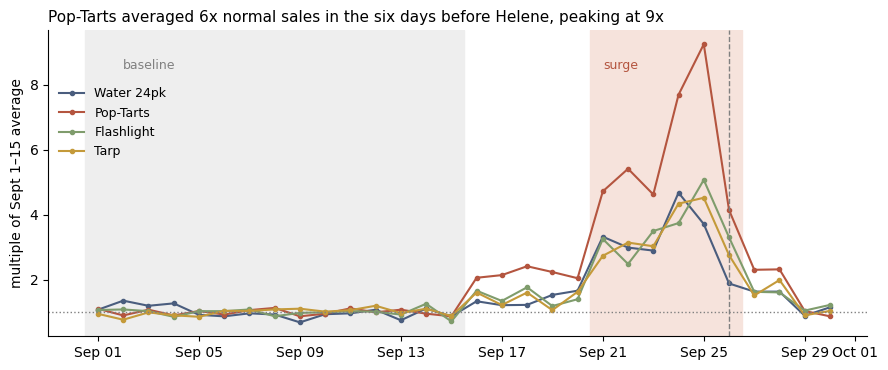

In [3]:
# TODO: the chart
import matplotlib.dates as mdates
top = ['Water 24pk', 'Pop-Tarts', 'Flashlight', 'Tarp']
colors = ['#4a5d7e', '#b4553f', '#7f9c6c', '#c49a3a']
indexed = daily / daily.loc[BASE_START:BASE_END].mean()
landfall = pd.Timestamp('2024-09-26')

fig, ax = plt.subplots(figsize=(9, 3.8))
half = pd.Timedelta(hours=12)
ax.axvspan(pd.Timestamp(BASE_START) - half, pd.Timestamp(BASE_END) + half, color='#eeeeee', zorder=0)
ax.axvspan(pd.Timestamp(SURGE_START) - half, pd.Timestamp(SURGE_END) + half, color='#f6e3dc', zorder=0)
for col, color in zip(top, colors):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.text(pd.Timestamp('2024-09-02'), 8.5, 'baseline', fontsize=9, color='gray')
ax.text(pd.Timestamp('2024-09-21'), 8.5, 'surge', fontsize=9, color='#b4553f')
ax.set_title('Pop-Tarts averaged 6x normal sales in the six days before Helene, peaking at 9x', loc='left', fontsize=11)
ax.set_ylabel('multiple of Sept 1–15 average')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0, 0.85))
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Q1 answer, in one sentence a manager could read:** _..._

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKUs: 45 -> canonical products: 20
Largest consolidated families:
product
Pop-Tarts       4
AA Batteries    3
Monopoly        3
Water 24pk      3
Chips           2

Assertion passed: total units 47,897 before and after consolidation
Best Pop-Tart SKU ranks #2 of 45 SKUs in storm-week units; consolidated Pop-Tarts rank #1 of 20 products


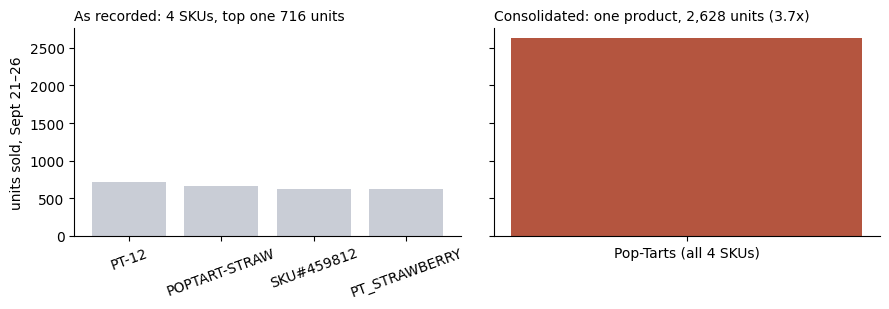

In [4]:
# TODO
n_skus = d['sku'].nunique()
n_products = d['product'].nunique()
family_sizes = d.groupby('product')['sku'].nunique().sort_values(ascending=False)
print(f'Distinct SKUs: {n_skus} -> canonical products: {n_products}')
print('Largest consolidated families:')
print(family_sizes.head(5).to_string())

assert d['product'].notna().all(), 'some SKUs are not mapped'
assert d['quantity'].sum() == d.groupby('product')['quantity'].sum().sum(), 'unit totals changed'
for prod, grp in d.groupby('product'):
    assert grp.groupby('sku')['quantity'].sum().sum() == grp['quantity'].sum()
print('\nAssertion passed: total units', f"{d['quantity'].sum():,}", 'before and after consolidation')

# before vs after: Pop-Tarts during the surge window
storm = d[d['date'].between(SURGE_START, SURGE_END)]
pt = storm[storm['product'] == 'Pop-Tarts']
fragmented = pt.groupby('sku')['quantity'].sum().sort_values(ascending=False)
consolidated = fragmented.sum()

sku_rank = storm.groupby('sku')['quantity'].sum().rank(ascending=False)
prod_rank = storm.groupby('product')['quantity'].sum().rank(ascending=False)
print(f'Best Pop-Tart SKU ranks #{int(sku_rank[fragmented.index].min())} of {len(sku_rank)} SKUs in storm-week units;'
      f' consolidated Pop-Tarts rank #{int(prod_rank["Pop-Tarts"])} of {len(prod_rank)} products')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: 4 SKUs, top one {fragmented.max()} units', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(['Pop-Tarts (all 4 SKUs)'], [consolidated], color='#b4553f')
axes[1].set_title(f'Consolidated: one product, {consolidated:,} units ({consolidated/fragmented.max():.1f}x)',
                  fontsize=10, loc='left')
axes[0].set_ylabel('units sold, Sept 21–26')
for ax in axes:
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Q2 answer:** _..._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
API call worked on attempt 1
weather rows: 360 | stores: 12 | source: live: Open-Meteo archive API
rows before join: 360 | after join: 360 | store-days missing weather: 0

days: 30 | stores: 12
units vs precip_mm: r = -0.15  (n = 360 store-days)
units vs max_wind_kmh: r = 0.20  (n = 360 store-days)
units vs precip_2_days_later: r = 0.01  (n = 336 store-days)
units vs wind_2_days_later: r = 0.68  (n = 336 store-days)


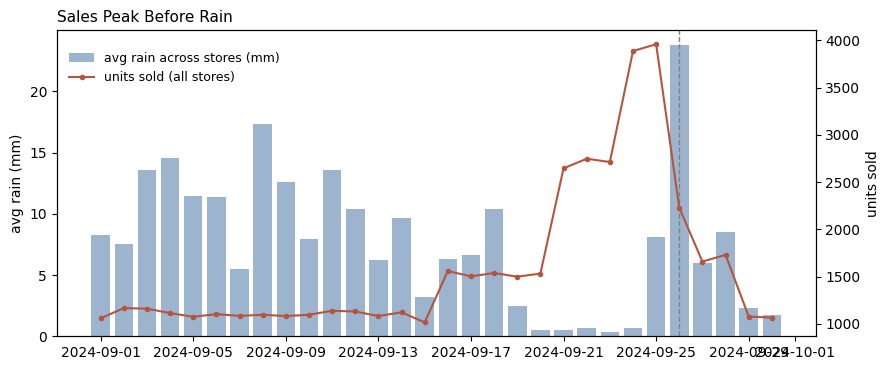

In [5]:
# TODO
import requests, time

def get_weather(url, params, max_tries=3):
  for attempt in range(1, max_tries+1):
    try:
      response = requests.get(url, params=params)
      response.raise_for_status()
      print("API call worked on attempt", attempt)
      return response.json()
    except Exception as e:
      print("Attempt", attempt, "failed:", e)
      if attempt < max_tries:
        time.sleep(2 * attempt)
  return None

stores = pd.read_csv(f'{REPO_PATH}/data/store_locations.csv')
stores['store_id'] = stores['store_id'].apply(clean_store_id)
stores = stores.drop_duplicates(subset='store_id')
stores.loc[stores['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]

# daily weather for each store
url = "https://archive-api.open-meteo.com/v1/archive"
all_weather = []
for i in range(len(stores)):
  store = stores.iloc[i]
  params = {
    "latitude": store['latitude'],
    "longitude": store['longitude'],
    "start_date": "2024-09-01",
    "end_date": "2024-09-30",
    "daily": "precipitation_sum,wind_speed_10m_max",
    "timezone": "America/New_York"
  }
  data = get_weather(url, params)
  if data is not None:
    w = pd.DataFrame({
        'date': pd.to_datetime(data['daily']['time']),
        'precip_mm': data['daily']['precipitation_sum'],
        'max_wind_kmh': data['daily']['wind_speed_10m_max'],
    })
    w['store_id'] = store['store_id']
    w['source'] = 'live: Open-Meteo archive API'
    all_weather.append(w)
  else:
    print("Skipping", store['store_id'], "because the call failed")
  time.sleep(1)

weather = pd.concat(all_weather, ignore_index=True)
print('weather rows:', len(weather), '| stores:', weather['store_id'].nunique(), '| source:', weather['source'].iloc[0])

# validated join: one row per store per day
store_day = d.groupby(['store_id', 'date'])['quantity'].sum().reset_index(name='units')
rows_before = len(store_day)
joined = store_day.merge(weather, on=['store_id', 'date'], how='left', validate='one_to_one')
rows_after = len(joined)
print('rows before join:', rows_before, '| after join:', rows_after,
      '| store-days missing weather:', joined['precip_mm'].isna().sum())
assert rows_before == rows_after

# correlation: same-day weather, and weather 2 days later (people buy BEFORE the storm hits)
joined = joined.sort_values(['store_id', 'date'])
joined['precip_2_days_later'] = joined.groupby('store_id')['precip_mm'].shift(-2)
joined['wind_2_days_later'] = joined.groupby('store_id')['max_wind_kmh'].shift(-2)
print('\ndays:', joined['date'].nunique(), '| stores:', joined['store_id'].nunique())
for col in ['precip_mm', 'max_wind_kmh', 'precip_2_days_later', 'wind_2_days_later']:
    sub = joined.dropna(subset=[col])
    print(f'units vs {col}: r = {sub["units"].corr(sub[col]):.2f}  (n = {len(sub)} store-days)')

# chart: all stores combined, units vs average rain
state = joined.groupby('date').agg(units=('units', 'sum'), precip_mm=('precip_mm', 'mean'))
fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.bar(state.index, state['precip_mm'], color='#9db4cf', label='avg rain across stores (mm)')
ax1.set_ylabel('avg rain (mm)')
ax2 = ax1.twinx()
ax2.plot(state.index, state['units'], color='#b4553f', marker='o', ms=3, label='units sold (all stores)')
ax2.set_ylabel('units sold')
ax1.axvline(pd.Timestamp('2024-09-26'), ls='--', color='gray', lw=1)
ax1.set_title('Sales Peak Before Rain', loc='left', fontsize=11)
fig.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0.07, 0.88))
plt.tight_layout(); plt.show()

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [6]:
progress = {
    'q1_multiple': 6.0,            # TODO: a number
    'q1_baseline_window': 'Sept 1–15, 2024 (surge window Sept 21–26)',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 3,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 6.0
PASS - q1_baseline_window = Sept 1–15, 2024 (surge window Sept 21–26)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_